# 전처리_열환경지수_검토전_ver1

2021~2025년 서울시 여름철 13시 열환경과 행정동별 고령인구를 전처리한다.

## 확정한 기준

| 항목 | 적용값 |
|---|---|
| 기간·시간 | 2021~2025년 6월 1일~8월 31일, 13시 |
| 계산 위치 | 100m 간격, 5개년 같은 좌표 |
| 공간 보간 | 같은 날 원관측 3곳, IDW(거리제곱 역수), d3≤3km·관측망 내부 |
| 센서 밀도 구간 | d3≤1km / 1~2km / 2~3km / >3km |
| 열환경지수 | 실측·결측 보완·공간 보간으로 얻은 일별 체감온도 합 ÷ 위치별 유효 산출일 |
| 고령인구 수 | 전체≥4,500명 / 여성≥2,500명 / 남성≥2,000명 |
| 고령인구 비율 | 각 집단의 65세 이상 인구 ÷ 해당 집단 전체 인구 ≥20% |
| 열환경 탐색 | 여름 평균 체감온도≥33℃, ≥35℃; 일별 초과 빈도 병기 |

혼합점수는 기존 방식을 유지한다. 인구 수·비율을 각각 2021년 해당 집단의 분포에 대한 백분위로 바꾸어 50%씩 합산하고, 그 집단의 2021년 혼합점수 75백분위를 공통 경계로 사용한다. 수·비율의 확정값과 혼합점수는 세 가지 독립된 비교 방식이다.

## 실행 방법과 자료의 의미

1. 이 노트북과 `경계` 폴더를 같은 폴더에 두고 그 폴더를 작업 위치로 열어 실행한다.
2. 첫 설정 셀에서 `DATA`가 원자료가 있는 경로인지 확인한다. 필요한 패키지는 아래 설치 안내를 사용한다.
3. 위에서부터 실행한다. 전체 S-DoT 원자료를 다시 읽으므로 시간이 걸릴 수 있으며, 결과는 새 `결과` 하위 폴더에 저장된다.

제공된 인구 파일은 날짜·시간이 없는 연간 고령자현황이다. 해당 연간 열을 그대로 사용하고 `pop_basis`에 출처를 표시한다. 현재 위치표를 과거에 적용한 센서는 `coord_basis`로 가정을 표시한다. 실제 과거 위치 이력이 확보되면 `POSITION_HISTORY`로 연결할 수 있다.

**보완값은 유효값이다.** 출처별 일수를 저장하는 목적은 자료 근거를 보여주기 위한 것이다. 같은 위치·날짜의 체감온도를 한 번만 합산한다. 센서가 없는 계산 위치에서도 채택한 보간값은 유효일에 포함된다.

100m 계산 간격은 100m 단위 관측 정확도의 보증이 아니다. 연도 비교는 공통 유효 공간에서 수행하며, 행정동 경계는 각 연도의 경계를 쓴다. 경계 변경이 있는 동의 인구 추이는 경계 변동도 함께 검토해야 한다.

현재 계산은 수요 후보까지이다. 부록의 공급 연결 함수에는 기존 건물·가로수·시설의 실제 13시 그늘 폴리곤을 입력한다. 시설 위치점만으로 그늘 면적이나 최종 설치 순위를 확정하지 않는다.

## 출처

- [서울시 S-DoT 환경정보](https://data.seoul.go.kr/dataList/OA-15969/S/1/datasetView.do)
- [기상청 체감온도 산출식](https://data.kma.go.kr/climate/windChill/selectWindChillChart.do?pgmNo=111)
- [QGIS 공간 보간 설명](https://docs.qgis.org/3.44/ko/docs/gentle_gis_introduction/spatial_analysis_interpolation.html)
- 행정동 경계: SGIS 자료를 가공한 vuski/admdongkor의 각 연도 7월 1일 서울 부분. 공공누리 제1유형 출처 표시. [고정 버전](https://github.com/vuski/admdongkor/tree/d5d5a821c8de6cc337d47eeca604d7af76271c9b/parquet)

기존 `데이터_전처리_건물파이프라인.ipynb`는 보존한다. 입력 설정, 행정동 집계, S-DoT 처리, 인구 기준, 공급과의 공간 결합, 결과 검증 영역을 이 노트북의 처리와 연결해 활용할 수 있다.


In [1]:
# 필요할 때 한 번 설치하고 커널을 재시작합니다.
# %pip install pandas numpy scipy geopandas shapely pyproj pyogrio pyarrow openpyxl matplotlib contourpy

## 설정과 입력

모든 기준을 한곳에 둔다. 100m 위치는 5년간 고정한다. 인구 수는 전체 4,500명·여성 2,500명·남성 2,000명 이상, 비율은 각 집단 20% 이상이다. 원자료는 읽기만 하며 결과는 실행마다 새 폴더에 저장한다.

In [2]:
from pathlib import Path
import csv
import json
import re
import unicodedata
from collections import Counter
from datetime import datetime
from uuid import uuid4

import numpy as np
import pandas as pd
import geopandas as gpd
import shapely
from shapely.geometry import LineString
from scipy.spatial import cKDTree, Delaunay, QhullError
import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm
from matplotlib import colormaps
from contourpy import contour_generator

DATA = Path.home() / 'Desktop/2026/26-2 교수자-학습자/데이터 분석/datasets'
SENSORS = DATA / '지표면 온도/스마트 센서'
POP_DIR = DATA / '고령인구 분포/생활인구/행정동 단위'
HERE = Path.cwd()  # 배포 폴더에서 노트북을 실행한다.
BOUNDARIES = HERE / '경계'
POSITION_HISTORY = None  # 선택: serial, site, start, end, lon, lat 열을 가진 확인된 이력 CSV
EXPORT_ALL_DAILY = False  # True: 460일 × 기온·습도 선을 모두 내보냄
HOURLY_POP = None  # 선택: 서울 열린데이터광장 행정동 단위 내국인 생활인구 월별 CSV 폴더
YEARS = list(range(2021, 2026))
HOUR = 13
CRS = 5186
STEP_M = 100  # 사용자 확정: 5개년 동일한 100m 위치에서 계산. 실제 관측 해상도와는 구분
MAX_D3_M = 3000  # 사용자 확정: 3km 이내 공간 추정. 2~3km도 유효값에 포함하고 밀도를 표시
MIN_MONTH_DAYS = 0  # 월별 일수는 기록만 한다. 보완값을 포함해 산출된 날을 모두 이용
MAX_TIME_GAP = None  # 1~3일 선형, 4일 이상 앞뒤 원값 평균. 양끝 원값이 없으면 미해결
THRESHOLD_ON = 'AT'  # 기준 변수: AT=13시 체감온도, Ta=13시 기온
TEMPS = (33, 35)
ELDER_COUNT_CUTS = {'전체': 4500, '여성': 2500, '남성': 2000}  # 사용자 확정, 매년 같은 기준
ELDER_SHARE_CUT = 0.20  # 사용자 확정: 전체/여성/남성 각각 해당 집단의 인구가 분모
POP_Q = 0.75  # 혼합점수만 기존 방식 유지: 2021년 혼합점수의 75백분위
DENSITY_EDGES_M = (1000, 2000, 3000)  # d3 ≤1km / 1~2km / 2~3km / >3km
SOURCE_CODES = {0: '미해결', 1: '당일_공간보간', 2: '시간_선형보완', 3: '시간_평균보완'}
DAILY_EXAMPLE = '07-15'  # 날짜별 기온·습도 등치선 예시. 일별 전체 값은 별도 저장
assert HOUR == 13, '시각 복원 규칙은 팀 기준시각 13시에 맞춰져 있습니다.'
assert THRESHOLD_ON in ('AT', 'Ta') and STEP_M > 0 and MAX_D3_M > 0
RUN = HERE/'결과'/(datetime.now().strftime('%Y%m%d_%H%M%S')+'_'+uuid4().hex[:6])
RUN.mkdir(parents=True)
if not SENSORS.is_dir() or not POP_DIR.is_dir():
    raise FileNotFoundError('설정 셀의 DATA, SENSORS, POP_DIR를 확인하세요.')
def nfc(value):
    return unicodedata.normalize('NFC', str(value)).strip()
def encoding(path):
    import codecs
    with path.open('rb') as stream:
        head = stream.read(65536)
    try:
        codecs.getincrementaldecoder('utf-8-sig')().decode(head, final=False)
        return 'utf-8-sig'
    except UnicodeDecodeError:
        return 'cp949'
def write_table(frame, name):
    frame.to_csv(RUN/name, index=False, encoding='utf-8-sig')
def summer(year):
    return pd.date_range(f'{year}-06-01', f'{year}-08-31')
bd = {y:gpd.read_parquet(BOUNDARIES/f'seoul_dong_{y}0701.parquet').to_crs(CRS) for y in YEARS}
for g in bd.values():
    g['geometry'] = g.geometry.make_valid()
    assert g.dong_code.is_unique and g.geometry.notna().all()
city = {y:g.geometry.union_all() for y,g in bd.items()}
common_city = city[YEARS[0]]
for y in YEARS[1:]:
    common_city = common_city.intersection(city[y])
settings = dict(hour=HOUR, years=YEARS, step_m=STEP_M, max_third_neighbor_m=MAX_D3_M,
                min_month_days=MIN_MONTH_DAYS, max_time_gap=MAX_TIME_GAP, threshold_on=THRESHOLD_ON,
                thresholds=TEMPS, elder_count_cuts=ELDER_COUNT_CUTS, elder_share_cut=ELDER_SHARE_CUT,
                mixed_score_quantile=POP_Q, density_edges_m=DENSITY_EDGES_M, source_codes=SOURCE_CODES, historical_locations=str(POSITION_HISTORY), hourly_population=str(HOURLY_POP), crs=CRS)
(RUN/'설정.json').write_text(json.dumps(settings,ensure_ascii=False,indent=2),encoding='utf-8')
print('결과 폴더', RUN)

결과 폴더 /Users/jiwonjung/.codex/.chatgpt-projects/g-p-6aa4f12a5c8c8191a771a8f120686fbb/outputs/열환경지수_검토전_ver1/결과/20261111_094746_1d9753


## 연도별 시각 복원 및 13시 추출

2021~2022년 전송시각의 정밀도 손실과 2023년 AM/PM 누락에 대응한다. 사용한 시각 규칙은 점검표에 기록한다. 실제 측정시각을 복원할 근거가 제한적인 행은 등록시각을 대용한 사실을 남긴다.

In [3]:
def read_target_hour(path, year):
    enc = encoding(path)
    rows = []
    audit = Counter()
    with path.open('rb') as stream:
        header = next(csv.reader([stream.readline().decode(enc)]))
        idx = {s.strip():i for i,s in enumerate(header)}
        old = '전송시간' in idx
        reg = idx['등록일자' if old else '등록일시']
        ms = idx['전송시간' if old else '측정시간']
        t = idx['기온(℃)' if old else '온도 평균(℃)']
        h = idx['상대습도( %)' if old else '습도 평균(%)']
        # 최신 64필드 행에도 원래 58개 열의 인덱스가 유지된다.
        for line in stream:
            audit['file_rows'] += 1
            if old:
                if b' 13:' not in line:
                    continue
            elif b'_13:' not in line and not (year==2023 and b'_01:' in line):
                continue
            row = next(csv.reader([line.decode(enc)]))
            if len(row) <= max(reg,ms,t,h):
                audit['short_row'] += 1
                continue
            reg_text = row[reg].strip()
            measured = row[ms].strip()
            if old:
                match = re.fullmatch(r'(\d{4}-\d\d-\d\d) 13:\d\d(?::\d\d)?',reg_text)
                if not match:
                    continue
                day = match[1]
                clock = '등록13시_대용'
                if re.fullmatch(r'\d{12}(?:\d{2})?', measured):
                    if measured[:10] != day.replace('-','')+'13':
                        audit['legacy_clock_conflict'] += 1
                        continue
                    clock='전송13시_일치'
            else:
                stamp = re.fullmatch(r'(\d{4}-\d\d-\d\d)_(\d\d):(\d\d):\d\d',measured)
                if not stamp:
                    audit['invalid_measure_clock'] += 1
                    continue
                day, hour, minute = stamp.groups()
                if year==2023 and hour=='01':
                    # 12시간 표기에서 AM/PM 누락. 같은 날 오후에 0~90분 이내 등록된 경우만 복원.
                    r = re.fullmatch(r'(\d{4}-\d\d-\d\d) (\d{1,2}):(\d\d)(?::\d\d)?',reg_text)
                    if not r or r[1]!=day or not (0 <= (int(r[2])-13)*60+int(r[3])-int(minute) <=90):
                        audit['01_not_confirmed_as_13'] += 1
                        continue
                    clock='측정01시_등록으로13시복원'
                elif hour=='13':
                    clock='측정13시'
                else:
                    continue
            if not (f'{year}-06-01' <= day <= f'{year}-08-31'):
                continue
            audit[clock] += 1
            rows.append((day,row[idx['시리얼']].strip(),row[t],row[h],clock))
    return pd.DataFrame(rows,columns=['date','serial','Ta','RH','clock']), dict(audit)

raw_years, file_reports = {}, []
for year in YEARS:
    dirs=[d for d in SENSORS.glob(f'{year}*') if d.is_dir()]
    if len(dirs)!=1: raise ValueError(f'{year}년 센서 폴더가 하나여야 합니다: {dirs}')
    files=sorted(p for p in dirs[0].rglob('*.csv') if not p.name.startswith(('.', '~')))
    if not files: raise FileNotFoundError(dirs[0])
    pieces=[]
    for path in files:
        part, audit=read_target_hour(path,year)
        file_reports.append(dict(year=year,file=path.name,rows_13=len(part),**audit))
        pieces.append(part)
    raw=pd.concat(pieces,ignore_index=True)
    for col,low,high in [('Ta',-5,55),('RH',0,100)]:
        values=pd.to_numeric(raw[col],errors='coerce')
        valid=values.between(low,high)
        if col=='RH':valid &= values.gt(0)
        raw[col]=values.where(valid)
    raw_years[year]=raw
    print(year, '입력 파일',len(files),'13시 행',len(raw),'기록일',raw.date.nunique())
write_table(pd.DataFrame(file_reports),'입력파일_시각점검.csv')

2021 입력 파일 14 13시 행 84912 기록일 91
2022 입력 파일 14 13시 행 93377 기록일 87
2023 입력 파일 14 13시 행 96246 기록일 92
2024 입력 파일 3 13시 행 91755 기록일 90
2025 입력 파일 66 13시 행 79567 기록일 92


## 위치표와 고정 추정 지점

시리얼을 좌표표와 연결한다. 과거 시리얼이 여러 위치를 가리키면 좌표를 확정하지 않는다. 확인된 운영 이력표가 없으면 현재 위치를 과거에도 유지했다고 가정하며 이를 결과에 표시한다. 100m는 계산 간격이며 관측 정확도를 의미하지 않는다.

In [4]:
locfiles=[p for p in SENSORS.glob('*.xlsx') if '설치 위치정보' in nfc(p.name) and not p.name.startswith('~')]
if len(locfiles)!=1: raise ValueError('설치 위치표 파일을 확인하세요.')
loc=pd.read_excel(locfiles[0],dtype=str)
loc=loc.rename(columns={'모델 시리얼(*)':'site','위도':'lat','경도':'lon'})
loc['site']=loc.site.str.strip()
for c in ['lat','lon']:loc[c]=pd.to_numeric(loc[c],errors='coerce')
if loc.site.isna().any() or not loc.site.is_unique: raise ValueError('위치표 현재 시리얼 중복/누락')
pairs=loc.melt(id_vars='site',value_vars=[c for c in loc if '변경 전 시리얼' in c],value_name='raw')[['site','raw']]
pairs=pd.concat([pairs,loc[['site']].assign(raw=loc.site)]).dropna()
pairs['raw']=pairs.raw.str.strip()
pairs=pairs[pairs.raw!=''].drop_duplicates()
ambiguous=set(pairs.groupby('raw').site.nunique().loc[lambda s:s>1].index)
serial_map=pairs[~pairs.raw.isin(ambiguous)].set_index('raw').site.to_dict()
sites=gpd.GeoDataFrame(loc[['site','lat','lon']],geometry=gpd.points_from_xy(loc.lon,loc.lat),crs=4326).to_crs(CRS)
sites=sites[sites.lon.notna() & sites.lat.notna()].set_index('site')
sites['coord_basis']='2026년3월_위치표_과거위치가정'
history=pd.DataFrame()
if POSITION_HISTORY is not None:
    history=pd.read_csv(POSITION_HISTORY,dtype={'serial':str,'site':str})
    for col in ['start','end']:
        history[col]=pd.to_datetime(history[col],errors='raise').dt.strftime('%Y-%m-%d')
    if history[['serial','site','start','end','lon','lat']].isna().any().any() or (history.start>history.end).any():
        raise ValueError('위치 이력의 날짜·좌표를 확인하세요.')
    for _,group in history.sort_values('start').groupby('serial'):
        if (group.start.iloc[1:].to_numpy()<=group.end.cummax().iloc[:-1].to_numpy()).any():
            raise ValueError('같은 시리얼의 운영기간이 겹칩니다.')
    # 이전은 별도 site로 보존. 같은 위치의 기기 교체는 같은 site로 지정 가능.
    history['site']='history_'+history.site
    xyhist=history[['site','lon','lat']].drop_duplicates()
    if xyhist.site.duplicated().any():raise ValueError('서로 다른 좌표에는 별도 site를 부여하세요.')
    sg=gpd.GeoDataFrame(xyhist,geometry=gpd.points_from_xy(xyhist.lon,xyhist.lat),crs=4326).to_crs(CRS).set_index('site')
    sites=pd.concat([sites,sg.assign(coord_basis='기간확인_이력표')])

xmin,ymin,xmax,ymax=shapely.total_bounds(list(city.values()))
xs=np.arange(np.floor(xmin/STEP_M)*STEP_M,xmax,STEP_M)+STEP_M/2
ys=np.arange(np.floor(ymin/STEP_M)*STEP_M,ymax,STEP_M)+STEP_M/2
xx,yy=np.meshgrid(xs,ys)
boxes=shapely.box(xx.ravel()-STEP_M/2,yy.ravel()-STEP_M/2,xx.ravel()+STEP_M/2,yy.ravel()+STEP_M/2)
cells=gpd.GeoDataFrame({'cell':np.arange(xx.size),'x':xx.ravel(),'y':yy.ravel()},geometry=boxes,crs=CRS)
cells=cells.loc[cells.intersects(common_city)].copy().reset_index(drop=True)
cells.geometry=cells.geometry.intersection(common_city)
cells=cells[cells.area>0].reset_index(drop=True)
grid_xy=cells[['x','y']].to_numpy()
cells.to_parquet(RUN/'고정지점_면적셀.parquet',index=False)
records, joinlog, conflicts={}, [], []
for year,raw in raw_years.items():
    raw=raw.copy()
    raw['site']=raw.serial.map(serial_map)
    if not history.empty:
        raw.loc[raw.serial.isin(history.serial),'site']=None
        for event in history.itertuples(index=False):
            mask=raw.serial.eq(event.serial)&raw.date.between(event.start,event.end)
            raw.loc[mask,'site']=event.site
    within=set(sites.index[sites.geometry.covered_by(city[year])])
    status=np.select([raw.serial.isin(ambiguous)&raw.site.isna(),raw.site.isna(),~raw.site.isin(within)],
                     ['과거시리얼_다중위치','위치미연결','서울경계밖'],default='현재위치표에연결')
    status=np.where(raw.site.astype('string').str.startswith('history_').fillna(False)&raw.site.isin(within),'기간확인_이력표',status)
    joinlog.append(raw.assign(status=status).groupby(['serial','status'],as_index=False).size().assign(year=year))
    raw=raw[raw.site.isin(within)]
    group=raw.groupby(['date','site'])
    daily=group[['Ta','RH']].first()
    for c in ['Ta','RH']:
        conflict=group[c].nunique()>1
        for date,site in conflict[conflict].index:
            conflicts.append((year,date,site,c))
        daily.loc[conflict,c]=np.nan
    records[year]=daily.reset_index()
write_table(pd.concat(joinlog),'시리얼_위치연결.csv')
write_table(pd.DataFrame(conflicts,columns=['year','date','site','variable']),'중복값충돌.csv')

## 공간·시간 보완과 일별 체감온도

세 관측점의 거리 제곱 역수로 가중한다. 실제 관측 위치의 중복 좌표는 하나로 센다. d3 구간은 ≤1km / 1~2km / 2~3km / >3km이며 2~3km 보간값도 채택한다. 공간 추정은 3km 이내·관측망 내부에서 수행한다. 고도 보정은 표고 자료가 없어 적용하지 않았다.

In [5]:
def density_band(d3):
    """0=당일 관측점 3곳 미확보, 1=≤1km, 2=1~2km, 3=2~3km, 4=>3km."""
    band=np.zeros(np.shape(d3),dtype=np.uint8)
    good=np.isfinite(d3)
    band[good]=np.searchsorted(DENSITY_EDGES_M,np.asarray(d3)[good],side='left')+1
    return band

def field_at(xy, values, targets, with_density=False):
    """같은 날 원관측으로만 IDW 추정. 보완값·가상점은 다른 점의 관측 근거로 재사용하지 않는다."""
    valid=np.isfinite(values)
    # 같은 좌표에 겹친 장비는 하나의 관측 위치로 계산하여 밀도가 과장되지 않게 한다.
    coords,inverse=np.unique(xy[valid],axis=0,return_inverse=True)
    pred=np.full(len(targets),np.nan)
    d3=pred.copy();d1=pred.copy()
    n1km=np.zeros(len(targets),dtype=np.uint16)
    if len(coords):
        tree=cKDTree(coords)
        if with_density:
            d1=tree.query(targets,k=1)[0]
            n1km=tree.query_ball_point(targets,r=1000,return_length=True).astype(np.uint16)
    if len(coords)>=3:
        values_at_location=np.bincount(inverse,weights=values[valid])/np.bincount(inverse)
        distances,neighbors=tree.query(targets,k=3)
        d3=distances[:,2]
        try:
            inside=Delaunay(coords).find_simplex(targets,tol=1e-9)>=0
        except QhullError:
            inside=np.zeros(len(targets),dtype=bool)
        # 관측망 내부이며 세 번째 관측점까지 3km 이내인 위치만 공간 추정한다.
        ok=inside & (d3<=MAX_D3_M)
        weight=1/np.maximum(distances[ok],0.01)**2
        pred[ok]=(weight*values_at_location[neighbors[ok]]).sum(axis=1)/weight.sum(axis=1)
        # 원관측과 같은 좌표에서는 그 관측값을 보존한다.
        exact=distances[:,0]<0.01
        pred[exact]=values_at_location[neighbors[exact,0]]
    return (pred,d3,d1,n1km) if with_density else (pred,d3)

def wet_and_apparent(t,r):
    # Stull 습구온도와 기상청 여름철 식. RH는 %, arctan은 라디안이며 모든 연도에 같은 식 적용.
    w=(t*np.arctan(.151977*np.sqrt(r+8.313659))+np.arctan(t+r)-np.arctan(r-1.67633)
       +.00391838*r**1.5*np.arctan(.023101*r)-4.686035)
    at=-.2442+.55399*w+.45535*t-.0022*w*w+.00278*w*t+3.
    return w,at
assert np.isclose(wet_and_apparent(32.,70.)[1],33.32283844)
def bounded_gaps(known):
    known_idx=np.flatnonzero(known)
    for left,right in zip(known_idx[:-1],known_idx[1:]):
        if right-left>1 and (MAX_TIME_GAP is None or right-left-1<=MAX_TIME_GAP):
            yield left,right

## 센서 결측과 추정 지점의 시간 보완

동일 날짜 원관측으로 공간 보완한 뒤 남은 공백을 시간 보완한다. 양쪽 근거가 있는 1~3일 공백은 선형보간, 4일 이상은 양끝 평균이다. 양끝 자료가 없으면 결측으로 둔다. 긴 공백의 평균 보완은 극값을 완만하게 할 수 있으므로 출처와 일수를 함께 기록한다.

In [6]:
def complete_variable(raw,present,xy,calendar,year,var,cv):
    result=raw.copy()
    flag=np.where(np.isfinite(raw),'obs','missing').astype('U10')
    eligible=present.copy()
    for j in range(present.shape[1]):
        for left,right in bounded_gaps(present[:,j]):
            eligible[left+1:right,j]=True
    grid=np.full((len(calendar),len(grid_xy)),np.nan)
    d3=grid.copy();d1=grid.copy()
    n1km=np.zeros(grid.shape,dtype=np.uint16)
    grid_source=np.zeros(grid.shape,dtype=np.uint8)
    folds=((np.floor(xy[:,0]/2000)+3*np.floor(xy[:,1]/2000)).astype(int)%5)
    for i,day in enumerate(calendar):
        missing=np.where(eligible[i] & ~np.isfinite(raw[i]))[0]
        estimate,dist,nearest,count=field_at(xy,raw[i],np.vstack([grid_xy,xy[missing]]),with_density=True)
        grid[i]=estimate[:len(grid_xy)]
        grid_source[i,np.isfinite(grid[i])]=1
        d3[i]=dist[:len(grid_xy)]
        d1[i]=nearest[:len(grid_xy)]
        n1km[i]=count[:len(grid_xy)]
        filled=np.isfinite(estimate[len(grid_xy):])
        result[i,missing[filled]]=estimate[len(grid_xy):][filled]
        flag[i,missing[filled]]='space'
        # 각 달 세 날짜에서 공간 블록을 통째로 제외하고 실측에 대조한다.
        if day.day in (5,15,25):
            for fold in range(5):
                test=(folds==fold)&np.isfinite(raw[i])
                if not test.any(): continue
                estimates,distances=field_at(xy[~test],raw[i,~test],xy[test])
                cv.append(pd.DataFrame({'year':year,'date':day,'variable':var,'fold':fold,
                    'observed':raw[i,test],'predicted':estimates,'d3_m':distances}))
    for j in range(raw.shape[1]):
        for left,right in bounded_gaps(np.isfinite(raw[:,j])):
            days=np.arange(left+1,right)
            use=days[eligible[days,j] & ~np.isfinite(result[days,j])]
            if not len(use): continue
            a,b=raw[left,j],raw[right,j]
            short=right-left-1<=3
            result[use,j]=a+(b-a)*(use-left)/(right-left) if short else (a+b)/2
            flag[use,j]='time_lin' if short else 'time_mean'
    # 고정 추정 지점도 같은 날짜별 분포를 먼저 사용한다.
    # 하루의 공간 추정이 불가능하면 같은 좌표의 앞뒤 원래 공간 추정값으로 시간 보완한다.
    grid_original=grid.copy()
    for j in range(grid.shape[1]):
        for left,right in bounded_gaps(np.isfinite(grid_original[:,j])):
            use=np.arange(left+1,right)
            a,b=grid_original[left,j],grid_original[right,j]
            short=right-left-1<=3
            grid[use,j]=a+(b-a)*(use-left)/(right-left) if short else (a+b)/2
            grid_source[use,j]=2 if short else 3
    # 시간 보완을 하더라도 밀도 정보는 그날의 원관측 상태를 유지한다.
    return result,flag,grid,d3,d1,n1km,grid_source

## 위치별 평균과 일별 초과 빈도

H는 위치별 일별 체감온도의 평균이다. 실측·결측 보완·공간 보간을 모두 포함하며 동일 날짜를 중복으로 세지 않는다. 기온·습도를 여름 평균한 뒤 체감온도로 바꾸지 않고, 일별 체감온도를 먼저 계산한다.

In [7]:
def annual_stats(t,at,calendar,keys,key):
    source=at if THRESHOLD_ON=='AT' else t
    valid=np.isfinite(at)
    frame=pd.DataFrame({key:keys,'valid_days':valid.sum(axis=0)})
    for month in (6,7,8):
        frame[f'days_{month}']=valid[calendar.month==month].sum(axis=0)
    frame['eligible']=frame.valid_days.gt(0)
    n=frame.valid_days.replace(0,np.nan)
    # 한 위치의 하루는 한 번만 센다. 실측·결측 보완·공간 보간을 모두 합계와 분모에 포함.
    frame['H_C']=np.nansum(at,axis=0)/n
    frame['mean_threshold_variable']=np.where(valid,source,0).sum(axis=0)/n
    for q in TEMPS:
        frame[f'days_ge{q}']=(valid & (source>=q)).sum(axis=0)
        frame[f'rate_ge{q}']=frame[f'days_ge{q}']/n
    return frame

## 5개년 일별 계산과 센서 밀도 저장

sensor_daily는 실제 센서의 원값·보완값을, field_daily는 고정 계산 지점의 보간값을 보존한다. 두 위치 집합을 합쳐 같은 면적을 두 번 계산하지 않는다. 최종 면적 집계는 100m 고정 지점으로 한다. 날짜별 밀도 및 추정 출처는 품질 설명용이며 보완값을 H에서 제외하는 조건으로 쓰지 않는다.

In [8]:
cv=[]
density_years=[]
grid_stats={}
site_stats=[]
for year in YEARS:
    data=records[year]
    calendar=summer(year)
    keys=sorted(data.site.unique())
    xy=np.c_[sites.loc[keys].geometry.x,sites.loc[keys].geometry.y]
    dates=calendar.strftime('%Y-%m-%d')
    def matrix(col):
        return data.pivot(index='date',columns='site',values=col).reindex(index=dates,columns=keys).to_numpy()
    present=np.isfinite(data.assign(present=1).pivot(index='date',columns='site',values='present').reindex(index=dates,columns=keys).to_numpy())
    ta0,rh0=matrix('Ta'),matrix('RH')
    ta,tf,gt,dt,d1t,n1t,gft=complete_variable(ta0,present,xy,calendar,year,'Ta',cv)
    rh,rf,gr,dr,d1r,n1r,gfr=complete_variable(rh0,present,xy,calendar,year,'RH',cv)
    wet,at=wet_and_apparent(ta,rh)
    gw,ga=wet_and_apparent(gt,gr)
    raw_pair=np.isfinite(ta0)&np.isfinite(rh0)
    st=annual_stats(ta,at,calendar,keys,'site')
    st['year']=year
    st['obs_days']=raw_pair.sum(axis=0)
    st['imputed_days']=st.valid_days-st.obs_days
    for month in (6,7,8): st[f'obs_days_{month}']=raw_pair[calendar.month==month].sum(axis=0)
    # 주 열환경 지수 H_C는 실측과 모든 채택 보완값을 같은 비중으로 포함한다.
    for q in TEMPS:
        observed_source=at if THRESHOLD_ON=='AT' else ta
        st[f'obs_days_ge{q}']=(raw_pair & (observed_source>=q)).sum(axis=0)
    site_stats.append(st)
    def daily_frame(keys,key,columns):
        idx=pd.MultiIndex.from_product([calendar,keys],names=['date',key])
        return pd.DataFrame({c:a.reshape(-1) for c,a in columns.items()},index=idx).reset_index()
    daily_frame(keys,'site',dict(Ta_raw=ta0,RH_raw=rh0,Ta=ta,RH=rh,Ta_source=tf,RH_source=rf,
        Tw=wet,AT=at)).to_parquet(RUN/f'sensor_daily_{year}.parquet',index=False)
    # 원관측이 없는 고정 위치의 추정값도 유효 산출값이다. 센서 자료와 합쳐 이중으로 세지 않는다.
    # source_code는 추정 근거 표시용이며 지수 계산에서 보완값을 제외하는 필터가 아니다.
    field=daily_frame(cells.cell,'cell',dict(Ta=gt,RH=gr,Tw=gw,AT=ga,
        Ta_source_code=gft,RH_source_code=gfr,d3_T_m=dt,d3_RH_m=dr,
        d1_T_m=d1t,d1_RH_m=d1r,obs_points_1km_T=n1t,obs_points_1km_RH=n1r,
        density_band_T=density_band(dt),density_band_RH=density_band(dr)))
    assert not field.duplicated(['date','cell']).any()
    field.to_parquet(RUN/f'field_daily_{year}.parquet',index=False)
    del field
    gs=annual_stats(gt,ga,calendar,cells.cell.to_numpy(),'cell').assign(year=year)
    valid=np.isfinite(ga)
    same_day_space=(gft==1)&(gfr==1)&valid
    gs['same_day_spatial_days']=same_day_space.sum(axis=0)
    gs['time_completed_days']=(valid & ~same_day_space).sum(axis=0)
    assert (gs.same_day_spatial_days+gs.time_completed_days==gs.valid_days).all()
    grid_stats[year]=gs
    density=pd.DataFrame({'cell':cells.cell.to_numpy(),'year':year})
    for tag,third,count in [('T',dt,n1t),('RH',dr,n1r)]:
        # 밀도는 온도에 곱하지 않고, 어떤 관측 여건에서 추정했는지 설명하는 정보로 저장한다.
        bands=density_band(third)
        density[f'd3_{tag}_median_m']=np.nanmedian(third,axis=0)
        density[f'd3_{tag}_p90_m']=np.nanquantile(third,.9,axis=0)
        density[f'obs_points_1km_{tag}_mean']=count.mean(axis=0)
        for band,label in [(0,'under3points'),(1,'le1km'),(2,'gt1_le2km'),(3,'gt2_le3km'),(4,'gt3km')]:
            density[f'{tag}_days_{label}']=(bands==band).sum(axis=0)
    density_years.append(density)
    print(year,'실제 지점',len(keys),'고정 위치',len(cells),'유효 지점·일',np.isfinite(ga).sum())
site_summary=pd.concat(site_stats).merge(sites.reset_index()[['site','lon','lat','coord_basis']],on='site',validate='many_to_one')
write_table(site_summary,'센서_연도별_열환경.csv')
gpd.GeoDataFrame(site_summary,geometry=gpd.points_from_xy(site_summary.lon,site_summary.lat),crs=4326).to_file(
    RUN/'센서위치와_연도별지수.gpkg',layer='sensor_year',driver='GPKG')
cross=pd.concat(cv,ignore_index=True)
cross['error']=cross.predicted-cross.observed
cross['abs_error']=cross.error.abs()
cross['distance_bin']=pd.cut(cross.d3_m,[-1,500,1000,2000,MAX_D3_M,np.inf] if MAX_D3_M>2000 else [-1,MAX_D3_M,np.inf],duplicates='drop')
cross['distance_bin']=cross.distance_bin.astype('string')
cross.to_parquet(RUN/'공간검증_예측쌍.parquet',index=False)
write_table(cross.groupby(['year','variable','distance_bin'],observed=True).agg(
    tested=('observed','size'),predicted=('predicted','count'),MAE=('abs_error','mean'),bias=('error','mean')).reset_index(),'공간검증_오차.csv')
common=np.logical_and.reduce([grid_stats[y].eligible.to_numpy() for y in YEARS])
for y in YEARS:grid_stats[y]['common5']=common
annual=pd.concat(grid_stats.values(),ignore_index=True)
annual.to_parquet(RUN/'고정지점_연도별_열환경.parquet',index=False)
density_summary=pd.concat(density_years,ignore_index=True)
density_summary.to_parquet(RUN/'고정지점_연도별_센서밀도.parquet',index=False)
write_table(density_summary,'고정지점_연도별_센서밀도.csv')

2021 실제 지점 1095 고정 위치 61663 유효 지점·일 5187094
2022 실제 지점 1112 고정 위치 61663 유효 지점·일 5186654
2023 실제 지점 1100 고정 위치 61663 유효 지점·일 5140956
2024 실제 지점 1088 고정 위치 61663 유효 지점·일 5170758
2025 실제 지점 1065 고정 위치 61663 유효 지점·일 5125836


## 행정동 면적과 33·35도 노출

고정 지점이 대표하는 면적과 행정동의 실제 겹침 면적으로 가중한다. 연도 비교에는 5년 모두 유효 산출값이 있는 공통 지점을 사용한다. coverage는 동 전체에서 비교 가능한 비율이다. 33·35℃는 계절평균 탐색 기준이며 일별 초과율도 따로 저장한다.

In [9]:
heat_year=[]
for year in YEARS:
    dong=bd[year]
    parts=gpd.overlay(dong[['dong_code','geometry']],cells[['cell','geometry']],how='intersection',keep_geom_type=True)
    # 행정동 경계와 겹치는 실제 면적으로 가중한다. 센서가 몰린 곳의 단순 평균을 사용하지 않는다.
    parts['a']=parts.area
    parts=parts.merge(grid_stats[year],on='cell',validate='many_to_one')
    use=parts[parts.common5 & parts.a.gt(0)].copy()
    use['weighted_H']=use.a*use.H_C
    for q in TEMPS:
        use[f'area_ge{q}']=use.a*(use.mean_threshold_variable>=q)
        use[f'daily_ge{q}']=use.a*use[f'rate_ge{q}']
    nums=['a','weighted_H']+[f'{prefix}{q}' for q in TEMPS for prefix in ['area_ge','daily_ge']]
    totals=use.groupby('dong_code')[nums].sum()
    result=dong[['dong_code','gu','dong']].copy().set_index('dong_code')
    result['year']=year
    result['dong_m2']=dong.set_index('dong_code').geometry.area
    result['common_m2']=totals.a.reindex(result.index,fill_value=0)
    result['coverage']=result.common_m2/result.dong_m2
    result['H_C']=totals.weighted_H/totals.a
    for q in TEMPS:
        # season_share: 계절평균 기준 이상 면적. daily_exposure: 지점별 기준 이상 일률의 면적 가중 평균.
        result[f'season_share_ge{q}']=totals[f'area_ge{q}']/totals.a
        result[f'daily_exposure_ge{q}']=totals[f'daily_ge{q}']/totals.a
    heat_year.append(result.reset_index())
heat=pd.concat(heat_year,ignore_index=True)
assert heat.coverage.between(0,1+1e-7).all()
write_table(heat,'행정동_연도별_열환경과_고온면적.csv')

## 행정동 인구 처리

제공된 연도별 고령자현황 파일의 연간 값 열을 읽는다. 분기 평균을 만들지 않는다. 시간별 생활인구가 없는 현재 실행은 행정동별 연간 고령자현황으로 표시한다. 전체·여성·남성 각각의 인구가 해당 비율의 분모이다. 혼합점수는 기존의 2021년 기준 백분위 50:50 방식 및 기준연도 75백분위 경계를 유지한다.

In [10]:
def dong_key(name):
    text=nfc(name)
    text=re.sub(r'제(?=\d)','',text)
    return re.sub(r'[.·ㆍ,\s]','',text)
def annual_population():
    from itertools import groupby
    all_rows, issues = [], []
    def value(text):
        return pd.to_numeric(str(text).replace(',',''),errors='coerce')
    for year in YEARS:
        files=[p for p in POP_DIR.glob('*.csv') if nfc(p.name)==f'고령자현황_행정동_{year}.csv']
        if len(files)!=1: raise FileNotFoundError(f'{year} 행정동 원본 파일을 확인하세요.')
        # 제공 원본은 마지막 숫자 뒤의 닫는 따옴표가 누락되어 있다.
        # 마지막 줄의 수치 9개 필드까지만 보존하고, 불완전한 앞부분이 있으면 즉시 알린다.
        with files[0].open(encoding=encoding(files[0]),newline='') as stream:
            reader=csv.reader(stream)
            header=next(reader); raw=list(reader)
        col=next(i for i,h in enumerate(header) if h.strip()==f'{year} 년')
        if any(len(row)<col+1 or '\n' in row[0] for row in raw):raise ValueError(f'{year}: 인구 CSV 행 손상')
        issues.append({'year':year,'event':'마지막행_닫는따옴표누락_필드검증','detail':files[0].name})
        gu=None
        gu_names=set(bd[year].gu)
        for name,iterator in groupby(raw,key=lambda r:r[0].strip()):
            rows=list(iterator)
            if name in gu_names:
                gu=name
                continue
            if name in ['합계','소계','서울특별시'] or gu is None: continue
            labels=[r[1].strip() for r in rows]
            if '65세이상 인구' not in labels:raise ValueError(f'{year} {gu} {name}: 고령자 구분 없음')
            elderly_index=labels.index('65세이상 인구')
            general={r[1].strip():value(r[col]) for r in rows[:elderly_index]}
            if labels[elderly_index+1:elderly_index+3]!=['남자','여자']:
                raise ValueError(f'{year} {name}: 고령 남녀 계층 확인 필요')
            men=value(rows[elderly_index+1][col]);women=value(rows[elderly_index+2][col])
            total_elder=value(rows[elderly_index][col])
            if np.isfinite([men,women,total_elder]).all() and not np.isclose(men+women,total_elder):
                raise ValueError(f'{year} {gu} {name}: 고령 남녀 합계 불일치')
            for group,count,den in [('전체',total_elder,general.get('남자',np.nan)+general.get('여자',np.nan)),
                                   ('남성',men,general.get('남자',np.nan)),('여성',women,general.get('여자',np.nan))]:
                all_rows.append(dict(year=year,gu=gu,dong=name,group=group,elder=count,total=den,
                    pop_basis=f'원본_{year}년_열',source_file=files[0].name))
    p=pd.DataFrame(all_rows)
    p['key']=p.dong.map(dong_key)
    # 2022-12-23 일원2동→개포3동은 경계 불변 명칭변경. 연말 표와 7월 경계를 대응.
    p.loc[(p.year==2022)&p.gu.eq('강남구')&p.key.eq('개포3동'),'key']='일원2동'
    b=pd.concat([bd[y][['dong_code','gu','dong']].assign(year=y) for y in YEARS],ignore_index=True)
    b['key']=b.dong.map(dong_key)
    if b.duplicated(['year','gu','key']).any():raise ValueError('행정동 경계 구·동명 키 중복')
    out=p.merge(b[['year','gu','key','dong_code']],on=['year','gu','key'],how='left',validate='many_to_one')
    write_table(out[out.dong_code.isna()],'인구_경계미연결.csv')
    write_table(pd.DataFrame(issues),'인구_원본읽기_점검.csv')
    write_table(out,'행정동_연도별_고령자현황_원자료.csv')
    matched=out[out.dong_code.notna()].drop(columns=['gu','dong','key'])
    keys=['year','dong_code','group']
    if (matched.groupby(keys)[['elder','total']].nunique()>1).any().any():
        raise ValueError('명칭변경 전후 동일 행정동의 연간 인구가 서로 다릅니다.')
    return matched.groupby(keys,as_index=False).first()

def older_hourly(folder):
    """서울 내국인 행정동별 공식 CSV (기준일ID, 시간대구분, 행정동코드, 성·연령별 생활인구수)."""
    rows=[]
    for path in sorted(Path(folder).rglob('*.csv')):
        enc=encoding(path)
        header=list(pd.read_csv(path,encoding=enc,nrows=0).columns)
        names={nfc(c).replace(' ',''):c for c in header}
        required=['기준일ID','시간대구분','행정동코드','총생활인구수']
        if not set(required).issubset(names):continue
        ages={s:[n for n in names if n.startswith(s) and n.endswith('생활인구수')] for s in ['남자','여자']}
        if any(len(v)<3 for v in ages.values()):raise ValueError(f'성별 연령 열을 확인하세요: {path}')
        for group in ages:
            for band in ['65세부터69세','70세이상']:
                if group+band+'생활인구수' not in names:raise ValueError(f'65세 이상 구간 변경: {path}')
        cols=required+ages['남자']+ages['여자']
        for chunk in pd.read_csv(path,encoding=enc,usecols=[names[c] for c in cols],dtype=str,chunksize=100000):
            chunk=chunk.rename(columns={names[c]:c for c in cols})
            date=pd.to_datetime(chunk['기준일ID'],format='%Y%m%d',errors='coerce')
            keep=date.dt.year.isin(YEARS)&date.dt.month.isin([6,7,8])&pd.to_numeric(chunk['시간대구분'],errors='coerce').eq(HOUR)
            c=chunk[keep].copy()
            if c.empty:continue
            c['date']=date[keep]
            code=c['행정동코드'].str.strip().str.replace(r'\.0$','',regex=True)
            c['dong_code']=code.where(code.str.len()!=8,code+'00')
            vals=c[cols[3:]].apply(pd.to_numeric,errors='coerce')
            vals=vals.where(vals>=0)
            for sex,group in [('남자','남성'),('여자','여성')]:
                elder=vals[[sex+'65세부터69세생활인구수',sex+'70세이상생활인구수']].sum(axis=1,min_count=2)
                total=vals[ages[sex]].sum(axis=1,min_count=len(ages[sex]))
                rows.append(c[['date','dong_code']].assign(group=group,elder=elder,total=total))
            elderly=[s+b+'생활인구수' for s in ages for b in ['65세부터69세','70세이상']]
            rows.append(c[['date','dong_code']].assign(group='전체',elder=vals[elderly].sum(axis=1,min_count=4),total=vals['총생활인구수']))
    if not rows:raise ValueError('지정 폴더에서 여름 13시 내국인 행정동 자료를 찾지 못했습니다.')
    p=pd.concat(rows,ignore_index=True).drop_duplicates()
    if p.duplicated(['date','dong_code','group']).any():raise ValueError('같은 날짜·동·성별에서 서로 다른 인구값이 중복됩니다.')
    p=p.dropna(subset=['elder','total']).assign(year=lambda d:d.date.dt.year, month=lambda d:d.date.dt.month)
    stats=p.groupby(['year','dong_code','group']).agg(elder=('elder','mean'),total=('total','mean'),pop_days=('date','size'))
    months=p.groupby(['year','dong_code','group','month']).size().unstack(fill_value=0).reindex(columns=[6,7,8],fill_value=0)
    stats.loc[months.min(axis=1)<MIN_MONTH_DAYS,['elder','total']]=np.nan
    return stats.reset_index().assign(pop_basis='13시_내국인_생활인구')

pop=annual_population() if HOURLY_POP is None else older_hourly(HOURLY_POP)
ok=(pop.total>0)&pop.elder.between(0,pop.total)
pop.loc[~ok,['elder','total']]=np.nan
pop['elder_share']=pop.elder/pop.total
def baseline_percentile(values,reference):
    # 기준년도 경험누적분포의 중간순위. 결측은 결측으로 보존.
    ref=np.sort(reference.dropna().to_numpy())
    if not len(ref):return pd.Series(np.nan,index=values.index)
    return pd.Series((np.searchsorted(ref,values,'left')+np.searchsorted(ref,values,'right'))/(2*len(ref)),index=values.index).where(values.notna())
for sex in ('전체','여성','남성'):
    sel=pop.group.eq(sex)
    base=sel & pop.year.eq(YEARS[0])
    for c in ['elder','elder_share']:
        pop.loc[sel,c+'_pct']=baseline_percentile(pop.loc[sel,c],pop.loc[base,c])
    pop.loc[sel,'mixed_score']=0.5*(pop.loc[sel,'elder_pct']+pop.loc[sel,'elder_share_pct'])
    # 인구 수와 비율은 사용자 확정값을 적용하며, 연도별 분위수로 재설정하지 않는다.
    pop.loc[sel,'cut_elder']=ELDER_COUNT_CUTS[sex]
    pop.loc[sel,'cut_elder_share']=ELDER_SHARE_CUT
    # 혼합점수는 수/비율을 2021년 분포에 대한 백분위로 바꿔 각각 50% 반영한다.
    pop.loc[sel,'cut_mixed_score']=pop.loc[base,'mixed_score'].quantile(POP_Q)
write_table(pop,'행정동_고령인구_세가지기준.csv')
# 인구 연결 실패도 결과에 남긴다. 이름이 같아 구분이 불가능한 행정동은 합치지 않는다.
keys=heat.merge(pd.DataFrame({'group':['전체','여성','남성']}),how='cross')
demand=keys.merge(pop,on=['year','dong_code','group'],how='left',validate='one_to_one',indicator='pop_join')
demand['threshold_variable']=THRESHOLD_ON
for q in TEMPS:
    hot=demand[f'season_share_ge{q}']>0
    for c in ['elder','elder_share','mixed_score']:
        valid=(demand.coverage>0)&demand[c].notna()&demand['cut_'+c].notna()
        daily_hot=demand[f'daily_exposure_ge{q}']>0
        demand[f'daily_candidate_{q}_{c}']=(daily_hot & (demand[c]>=demand['cut_'+c])).astype('boolean').where(valid)
        demand[f'candidate_{q}_{c}']=(hot & (demand[c]>=demand['cut_'+c])).astype('boolean').where(valid)
write_table(demand,'행정동_33도35도_수요후보.csv')
print('인구 기준:',pop.pop_basis.unique(),'전체 연도·동 중 성별 전체 인구 연결',demand[demand.group=='전체'].elder.notna().sum(),'/',len(heat))

인구 기준: ['원본_2021년_열' '원본_2022년_열' '원본_2023년_열' '원본_2024년_열' '원본_2025년_열'] 전체 연도·동 중 성별 전체 인구 연결 2131 / 2131


## 지도와 등치선 내보내기

5개년 공통 색 범위로 연도별 평균 체감온도 등온선과 고령인구 지도를 만든다. 일별 기온·습도 분포는 모든 날짜의 수치로 저장하고 기본 등치선 예시는 7월 15일이다. daily_contours로 원하는 날짜를 내보내거나 EXPORT_ALL_DAILY를 켤 수 있다.

In [11]:
from shapely.plotting import patch_from_polygon
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize
MAPS=RUN/'지도'
MAPS.mkdir(exist_ok=True)
def lattice(values):
    z=np.full(xx.size,np.nan)
    z[cells.cell.to_numpy()]=np.asarray(values)
    return z.reshape(xx.shape)
def contour_features(z,levels,domain,variable):
    features=[]
    if not np.isfinite(z).any(): return features
    cg=contour_generator(x=xs,y=ys,z=np.ma.masked_invalid(z),corner_mask=False,line_type='Separate')
    for value in levels:
        for coords in cg.lines(float(value)):
            if len(coords)<2: continue
            geom=LineString(coords).intersection(domain)
            for part in shapely.get_parts(geom):
                if part.geom_type=='LineString' and part.length>0:
                    features.append({'value':float(value),'variable':variable,'geometry':part})
    return features
def save_lines(features,path):
    if features:
        gpd.GeoDataFrame(features,crs=CRS).to_crs(4326).to_file(path,driver='GeoJSON')
    else:
        path.write_text('{"type":"FeatureCollection","features":[]}',encoding='utf-8')

def daily_contours(year,date):
    """전체 460일에 대한 추정면은 field_daily에 저장. 필요한 날짜를 등치선으로 내보낸다."""
    date=pd.Timestamp(date)
    if date not in summer(year):raise ValueError('해당 연도의 6~8월 날짜가 필요합니다.')
    data=pd.read_parquet(RUN/f'field_daily_{year}.parquet',filters=[('date','=',date)]).set_index('cell').reindex(cells.cell)
    for var,step in [('Ta',1),('RH',5)]:
        z=lattice(data[var])
        finite=z[np.isfinite(z)]
        levels=np.arange(np.ceil(finite.min()/step)*step,finite.max(),step) if len(finite) else []
        features=contour_features(z,levels,common_city,var)
        save_lines(features,MAPS/f'{date:%Y%m%d}_{var}_등치선.geojson')
    return date.date()

eligible_h=annual.loc[annual.common5,'H_C'].dropna()
if eligible_h.empty:raise ValueError('5개년 모두 유효 산출값이 있는 추정 지점이 없습니다.')
# 개별 연도 지도에 표시하는 모든 값에 맞춰 공통 색 범위를 정한다.
map_h=annual.loc[annual.eligible,'H_C'].dropna()
levels=np.arange(np.floor(map_h.min()),np.ceil(map_h.max())+1,1)
if len(levels)<2:levels=np.array([levels[0]-1,levels[0]+1])
cmap=colormaps['YlOrRd'].resampled(len(levels)-1)
norm=BoundaryNorm(levels,cmap.N)
def base_map(ax,year):
    bd[year].plot(ax=ax,color='#e7e7e7',edgecolor='none')
    ax.set(xlim=(xmin,xmax),ylim=(ymin,ymax),aspect='equal')
    ax.set_axis_off()
for year in YEARS:
    z=lattice(grid_stats[year].H_C.where(grid_stats[year].eligible))
    features=contour_features(z,levels,common_city,'H_C')
    save_lines(features,MAPS/f'{year}_평균체감온도_등온선.geojson')
    fig,ax=plt.subplots(figsize=(7.2,6.1),layout='constrained')
    base_map(ax,year)
    patch=patch_from_polygon(common_city)
    patch.set_transform(ax.transData)
    ax.contourf(xs,ys,np.ma.masked_invalid(z),levels=levels,cmap=cmap,norm=norm,corner_mask=False,clip_path=patch)
    if features:
        gpd.GeoDataFrame(features,crs=CRS).plot(ax=ax,color='#6c3c29',linewidth=.35,alpha=.75)
    ax.set_title(f'Seoul | {year} summer, 13:00 KST')
    fig.colorbar(ScalarMappable(norm=norm,cmap=cmap),ax=ax,label='Mean apparent temperature (°C)',shrink=.76)
    ax.text(.01,.01,'Grey: insufficient or unmodelled coverage',fontsize=8,transform=ax.transAxes)
    fig.savefig(MAPS/f'{year}_열환경.png',dpi=150);plt.close(fig)
    export_dates=summer(year) if EXPORT_ALL_DAILY else [f'{year}-{DAILY_EXAMPLE}']
    for date in export_dates: daily_contours(year,date)
    # 같은 색 범위로 3개 그룹과 5개년을 비교한다. 실제 지도 파일에는 인구 자료의 성격을 표시.
    vmax=max(1,pop.elder.max())
    fig,axes=plt.subplots(1,3,figsize=(12,4.8),layout='constrained')
    basis='13:00 living population' if HOURLY_POP is not None else 'Annual population in supplied file'
    for ax,group,label in zip(axes,['전체','여성','남성'],['All','Women','Men']):
        sub=demand[(demand.year==year)&(demand.group==group)][['dong_code','elder']]
        view=bd[year].merge(sub,on='dong_code',validate='one_to_one')
        base_map(ax,year)
        view[view.elder.notna()].plot(ax=ax,column='elder',cmap='viridis',vmin=0,vmax=vmax,linewidth=0)
        ax.set_title(label)
    fig.suptitle(f'{year} | {basis}, age 65+')
    fig.colorbar(ScalarMappable(norm=Normalize(0,vmax),cmap='viridis'),ax=axes,label='Persons',shrink=.65)
    fig.savefig(MAPS/f'{year}_고령인구_전체_여성_남성.png',dpi=135);plt.close(fig)
dong_geo=pd.concat([bd[y].assign(year=y) for y in YEARS],ignore_index=True).merge(
    demand.drop(columns=['dong','gu']),on=['year','dong_code'],how='left',validate='one_to_many')
dong_geo.to_parquet(RUN/'행정동_공간결합_수요후보.parquet',index=False)

## 검증 및 결과 요약

확정 임계값, d3 경계, 최대 92일, 실측·보완 합계와 유효일, 행정동 연결키를 검증한다. 후보표는 현재 원자료와 가정에 따른 탐색 결과이다.

In [12]:
# 확정 경계값이 분위수 계산으로 덮어쓰이지 않았는지 확인한다.
for group,cut in ELDER_COUNT_CUTS.items():
    assert pop.loc[pop.group.eq(group),'cut_elder'].eq(cut).all()
assert pop.cut_elder_share.eq(0.20).all()
assert STEP_M==100 and tuple(DENSITY_EDGES_M)==(1000,2000,3000)
assert density_band(np.array([1000,1000.01,2000,2000.01,3000,3000.01,np.nan])).tolist()==[1,2,2,3,3,4,0]
assert (annual.same_day_spatial_days+annual.time_completed_days==annual.valid_days).all()
assert len(annual)==len(YEARS)*len(cells) and not annual.duplicated(['year','cell']).any()
assert site_summary.valid_days.between(0,92).all() and annual.valid_days.between(0,92).all()
assert (site_summary.obs_days+site_summary.imputed_days==site_summary.valid_days).all()
assert (annual.days_ge35<=annual.days_ge33).all() and (annual.days_ge33<=annual.valid_days).all()
assert (site_summary.days_ge35<=site_summary.days_ge33).all() and (site_summary.days_ge33<=site_summary.valid_days).all()
assert not demand.duplicated(['year','dong_code','group']).any() and len(demand)==3*len(heat)
assert len(list(MAPS.glob('*_열환경.png')))==len(YEARS)
for rate in ['season_share_ge33','season_share_ge35','daily_exposure_ge33','daily_exposure_ge35']:
    assert heat[rate].dropna().between(-1e-8,1+1e-8).all()
report=site_summary.groupby('year').agg(센서수=('site','size'),유효값있는센서수=('eligible','sum'),
    실측센서일=('obs_days','sum'),보완센서일=('imputed_days','sum')).reset_index()
report['공통고정지점수']=int(common.sum())
overall=demand[demand.group.eq('전체')].groupby('year')
report['행정동수']=report.year.map(overall.size())
report['인구값연결동수']=report.year.map(overall.elder.count())
for q in TEMPS:
    for method,label in [('elder','인구수'),('elder_share','인구비율'),('mixed_score','혼합')]:
        report[f'후보_{q}_{label}']=report.year.map(overall[f'candidate_{q}_{method}'].sum())
write_table(report,'실행요약.csv')
print(report.to_string(index=False))
print('GIS 좌표계 EPSG:5186 / GeoJSON만 WGS84. 결과:',RUN)

 year  센서수  유효값있는센서수  실측센서일  보완센서일  공통고정지점수  행정동수  인구값연결동수  후보_33_인구수  후보_33_인구비율  후보_33_혼합  후보_35_인구수  후보_35_인구비율  후보_35_혼합
 2021 1095      1095  84405  15551    55664   426      426          0           0         0          0           0         0
 2022 1112      1112  90968  10371    55664   426      426          0           0         0          0           0         0
 2023 1100      1097  83439  15532    55664   426      426          3           1         3          0           0         0
 2024 1088      1087  81818  14056    55664   426      426         33          27        27          0           0         0
 2025 1065      1061  49303  42392    55664   427      427          0           1         1          0           0         0
GIS 좌표계 EPSG:5186 / GeoJSON만 WGS84. 결과: /Users/jiwonjung/.codex/.chatgpt-projects/g-p-6aa4f12a5c8c8191a771a8f120686fbb/outputs/열환경지수_검토전_ver1/결과/20261111_094746_1d9753


## 기존 그늘 결과와 연결하는 공간 분석

기존 공급 자료와의 연결을 위한 부록이다. 설치 시점·좌표·매칭 상태를 기록하며 확인되지 않은 그늘 영역은 별도 입력이 필요하다.

In [13]:
def make_hot_zones(year, threshold):
    """공통 지점에서 기준 이상의 계절 평균을 가진 면을 행정동별로 자른다."""
    stats=grid_stats[year]
    selected=stats.loc[stats.common5 & stats.mean_threshold_variable.ge(threshold),'cell']
    zone=cells[cells.cell.isin(selected)][['cell','geometry']]
    if zone.empty:
        return gpd.GeoDataFrame(columns=['cell','dong_code','gu','dong','geometry'],geometry='geometry',crs=CRS)
    return gpd.overlay(zone,bd[year][['dong_code','gu','dong','geometry']],how='intersection')

def shade_quadrants(hot_zones, artificial_shade, other_shade):
    """모두 EPSG:5186 폴리곤. 빈 GeoDataFrame은 자료상 공급 없음, None은 아직 미입력."""
    if artificial_shade is None or other_shade is None:
        raise ValueError('그늘 사분면 계산에는 같은 기준시각의 인공·기타 그늘 영역이 필요합니다.')
    def union_of(frame):
        if not isinstance(frame,gpd.GeoDataFrame) or frame.crs is None:
            raise ValueError('좌표계가 지정된 GeoDataFrame이 필요합니다.')
        data=frame.to_crs(CRS).geometry.make_valid()
        if not data.geom_type.isin(['Polygon','MultiPolygon']).all():
            raise ValueError('그늘 영역에는 폴리곤을 사용하세요. 시설 점 위치는 시설 존재 집계에 사용합니다.')
        return data.union_all()
    artificial=union_of(artificial_shade)
    other=union_of(other_shade)
    rows=[]
    for item in hot_zones.to_crs(CRS).itertuples():
        for a,o,geom in [
            (False,False,item.geometry.difference(artificial).difference(other)),
            (False,True,item.geometry.intersection(other).difference(artificial)),
            (True,False,item.geometry.intersection(artificial).difference(other)),
            (True,True,item.geometry.intersection(artificial).intersection(other))]:
            if geom.is_empty or geom.area<=0:continue
            rows.append(dict(dong_code=item.dong_code,artificial=a,other=o,
                             priority=1 if not a and not o else 2 if not a else 0,
                             area_m2=geom.area,geometry=geom))
    result=gpd.GeoDataFrame(rows,geometry='geometry',crs=CRS) if rows else gpd.GeoDataFrame(
        columns=['dong_code','artificial','other','priority','area_m2','geometry'],geometry='geometry',crs=CRS)
    if len(hot_zones):
        assert np.isclose(result.area.sum(),hot_zones.area.sum(),rtol=1e-6)
    return result

def combine_demand_and_supply(year, threshold, group, artificial_shade, other_shade,
                              population_method='mixed_score'):
    """열환경×고령인구 조건의 교집합에 사분면 순위를 연결한다."""
    zones=make_hot_zones(year,threshold)
    people=demand[(demand.year==year)&demand.group.eq(group)].copy()
    many=people[people[population_method]>=people['cut_'+population_method]]
    zones=zones[zones.dong_code.isin(many.dong_code)]
    return shade_quadrants(zones,artificial_shade,other_shade)

# 2026 공급 적용 예시는 아래와 같다. 실제 그늘 폴리곤을 확보한 뒤 호출한다.
# additional_2026 = combine_demand_and_supply(
#     2025, 33, '전체', artificial_shade_2026, other_shade_2026)
# 결과의 수요 기준연도는 2025년, 공급 기준연도는 2026년으로 저장한다.
for y in YEARS:
    for threshold in TEMPS:
        zones=make_hot_zones(y,threshold)
        if len(zones):
            zones.to_parquet(RUN/f'고온구역_{y}_{threshold}.parquet',index=False)
print('33·35℃ 고온 구역 저장. 그늘 영역을 연결하면 사분면·고령인구 조건의 교집합을 계산합니다.')

33·35℃ 고온 구역 저장. 그늘 영역을 연결하면 사분면·고령인구 조건의 교집합을 계산합니다.


## 인공 그늘막 원본을 연도별 시설 위치로 정리

기존 공급 자료와의 연결을 위한 부록이다. 설치 시점·좌표·매칭 상태를 기록하며 확인되지 않은 그늘 영역은 별도 입력이 필요하다.

In [14]:
shade_files=[p for p in (DATA/'인공 그늘막').glob('*.xlsx') if '그늘막' in nfc(p.name) and not p.name.startswith('~')]
if len(shade_files)!=1: raise FileNotFoundError('인공 그늘막 원본을 확인하세요.')
shade_source=pd.read_excel(shade_files[0],header=4)
shade=shade_source.rename(columns={'시군구':'gu','관리번호':'facility_id','설치장소명':'name',
    '경도':'lon','위도':'lat','설치일시':'installed_at'})
for c in ['lon','lat']:shade[c]=pd.to_numeric(shade[c],errors='coerce')
shade['installed_at']=pd.to_datetime(shade.installed_at,errors='coerce',format='mixed')
shade=shade[shade.facility_id.notna()].copy()
shade['source_row']=shade.index+6
write_table(shade,'인공그늘막_원본표준화.csv')
usable=shade.lon.between(126,128)&shade.lat.between(37,38)
fac=gpd.GeoDataFrame(shade[usable],geometry=gpd.points_from_xy(shade.loc[usable,'lon'],shade.loc[usable,'lat']),crs=4326).to_crs(CRS)
facility_year=[]
for y in YEARS+[2026]:
    date=pd.Timestamp(f'{y}-08-01') if y<=2025 else pd.Timestamp('2026-09-10')
    sub=fac[fac.installed_at<=date].copy()
    current=bd[min(y,2025)][['dong_code','geometry']]
    joined=gpd.sjoin(sub,current,how='left',predicate='intersects').drop(columns='index_right')
    joined['supply_year']=y
    joined['snapshot_date']=date.strftime('%Y-%m-%d')
    joined['history_basis']='2026현존목록_설치일소급_철거이력미포함'
    facility_year.append(joined)
facility_year=gpd.GeoDataFrame(pd.concat(facility_year,ignore_index=True),crs=CRS)
facility_year.to_parquet(RUN/'인공그늘막_연도별_행정동위치.parquet',index=False)
write_table(facility_year.drop(columns='geometry'),'인공그늘막_연도별_행정동위치.csv')
print('인공 그늘막 시설 위치',len(fac),'좌표 누락',len(shade)-len(fac),'설치일 누락',fac.installed_at.isna().sum())

인공 그늘막 시설 위치 5198 좌표 누락 10 설치일 누락 286


## 버스정류장·스마트쉼터 위치와 연도 연결

기존 공급 자료와의 연결을 위한 부록이다. 설치 시점·좌표·매칭 상태를 기록하며 확인되지 않은 그늘 영역은 별도 입력이 필요하다.

In [15]:
bus_dir=DATA/'기타그늘요소/버스정류장'
bus_parts=[]
for year in YEARS:
    files=[p for p in bus_dir.iterdir() if '위치정보(' in nfc(p.name) and str(year) in nfc(p.name) and p.suffix in ['.csv','.xlsx']]
    if len(files)!=1:raise FileNotFoundError(f'{year} 버스정류장 위치 파일 확인')
    p=files[0]
    b=pd.read_excel(p) if p.suffix=='.xlsx' else pd.read_csv(p,encoding=encoding(p),low_memory=False)
    b=b.rename(columns={'STDR_DE':'date','NODE_ID':'node_id','STTN_NO':'ars','ARS_ID':'ars',
        'STTN_NM':'name','정류소명':'name','CRDNT_X':'lon','CRDNT_Y':'lat','X좌표':'lon','Y좌표':'lat'})
    b['ars']=pd.to_numeric(b.ars,errors='coerce').astype('Int64').astype('string').str.zfill(5)
    if year<=2023:
        b['date']=pd.to_datetime(b.date.astype(str),format='%Y%m%d',errors='coerce')
        b=b[b.date.between(f'{year}-06-01',f'{year}-08-31')]
        b=b.sort_values('date').drop_duplicates('node_id',keep='last')
    else:
        b['date']=pd.Timestamp(f'{year}-12-09')
    b['year']=year
    b['position_basis']='여름마지막월_스냅샷' if year<=2023 else '12월위치_여름대용'
    bus_parts.append(b[['year','node_id','ars','name','lon','lat','date','position_basis']])
bus=pd.concat(bus_parts,ignore_index=True)
bus=gpd.GeoDataFrame(bus,geometry=gpd.points_from_xy(bus.lon,bus.lat),crs=4326).to_crs(CRS)
bus.to_parquet(RUN/'버스정류장_연도별위치.parquet',index=False)
shelter_file=next(p for p in bus_dir.glob('*.xlsx') if '스마트쉼터 현황' in nfc(p.name))
shelter=pd.read_excel(shelter_file,header=3).dropna(subset=['시설명']).copy()
shelter['facility_id']='shelter_'+shelter.index.astype(str)
shelter['installed_year']=pd.to_numeric(shelter['설치년도'],errors='coerce')
shelter['ars']=shelter['설치장소'].astype(str).str.extract(r'(?<!\d)(\d{2})[- ]?(\d{3})(?!\d)').fillna('').agg(''.join,axis=1).replace('',pd.NA)
shelter_records=[]
for year in YEARS:
    valid=shelter[shelter.installed_year<=year]
    candidates=bus[bus.year.eq(year)]
    unique=candidates[~candidates.ars.duplicated(keep=False)]
    joined=valid.merge(unique[['ars','node_id','lon','lat','geometry']],on='ars',how='left',validate='many_to_one')
    joined['year']=year
    joined['location_match']=np.where(joined.geometry.notna(),'ARS_유일일치','주소또는중복ARS확인')
    shelter_records.append(joined)
shelter_records=gpd.GeoDataFrame(pd.concat(shelter_records,ignore_index=True),geometry='geometry',crs=CRS)
shelter_records.to_parquet(RUN/'스마트쉼터_연도별위치.parquet',index=False)
write_table(shelter_records.drop(columns='geometry'),'스마트쉼터_주소와매칭점검.csv')
print('스마트쉼터 위치 연결',shelter_records.geometry.notna().sum(),'/',len(shelter_records))

스마트쉼터 위치 연결 540 / 759


## 확인할 결과와 핵심 설명

실행 후 아래 표와 그림에서 확정 기준 및 계산 결과를 확인한다. 최종 설치 우선지에는 실제 13시 그늘 영역을 추가로 연결해야 한다.

완료: /Users/jiwonjung/.codex/.chatgpt-projects/g-p-6aa4f12a5c8c8191a771a8f120686fbb/outputs/열환경지수_검토전_ver1/결과/20261111_094746_1d9753
유효 산출일에는 채택된 결측 보완값과 공간 보간값이 모두 포함됩니다.


,year,센서수,유효값있는센서수,실측센서일,보완센서일,공통고정지점수,행정동수,인구값연결동수,후보_33_인구수,후보_33_인구비율,후보_33_혼합,후보_35_인구수,후보_35_인구비율,후보_35_혼합
0,2021,1095,1095,84405,15551,55664,426,426,0,0,0,0,0,0
1,2022,1112,1112,90968,10371,55664,426,426,0,0,0,0,0,0
2,2023,1100,1097,83439,15532,55664,426,426,3,1,3,0,0,0
3,2024,1088,1087,81818,14056,55664,426,426,33,27,27,0,0,0
4,2025,1065,1061,49303,42392,55664,427,427,0,1,1,0,0,0


,집단,고령인구수_이상,고령인구비율_이상
0,전체,4500,0.2
1,여성,2500,0.2
2,남성,2000,0.2


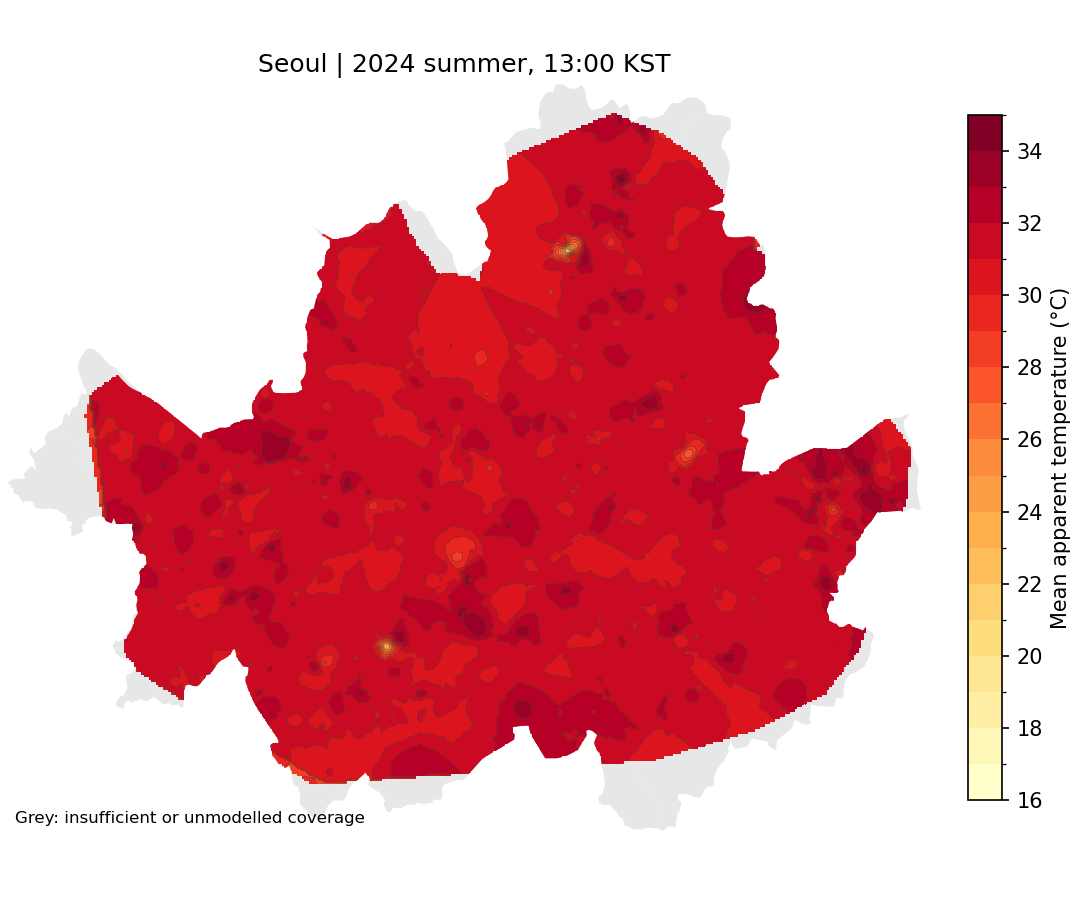

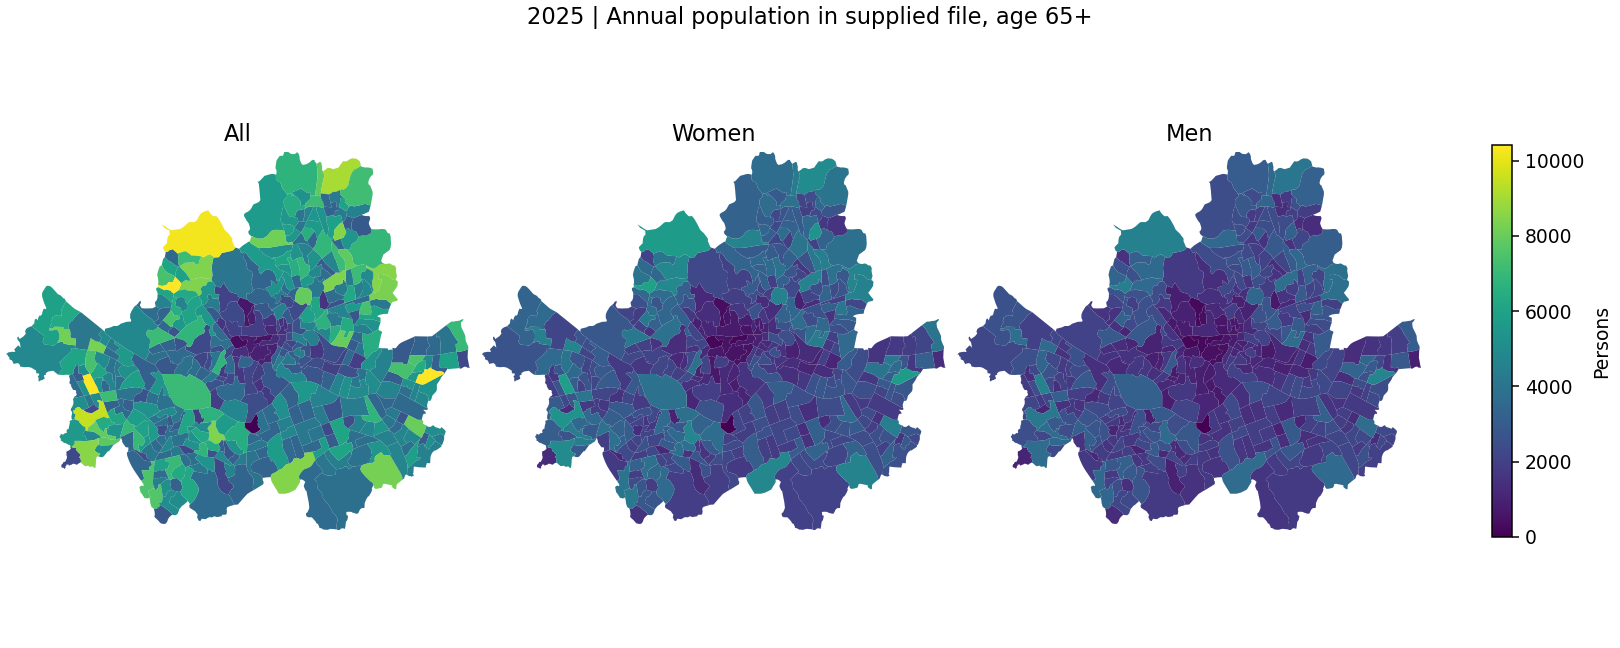

In [16]:
from IPython.display import display, Image
# 표의 후보는 열환경과 인구 조건의 교집합이며, 실제 그늘 공급을 반영한 최종 설치지는 아니다.
display(report)
display(pd.DataFrame({'집단':['전체','여성','남성'],
    '고령인구수_이상':[ELDER_COUNT_CUTS[g] for g in ['전체','여성','남성']],
    '고령인구비율_이상':[ELDER_SHARE_CUT]*3}))
# 저장된 결과를 노트북에서도 바로 확인할 수 있도록 대표 지도와 밀도 정보를 표시한다.
display(Image(filename=str(MAPS/'2024_열환경.png'),width=720))
display(Image(filename=str(MAPS/'2025_고령인구_전체_여성_남성.png'),width=1000))
print('완료:',RUN)
print('유효 산출일에는 채택된 결측 보완값과 공간 보간값이 모두 포함됩니다.')